### ELO328 - Procesamiento Digital de Imágenes
# Clase 5: Segmentación de imágenes
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción


<div align="center">
    <img src="img/clases.jpg" alt="" width="80%" align="center" />
</div>

**Segmentación:**
- Proceso de particionar una imagen digital en múltiples segmentos.
- Busca simplificar y/o cambiar la representación en algo que sea más fácil de analizar.
- Se utiliza para localizar objetos y regiones de interés.

**Objetivo:** Identificar grupos de píxeles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, fixed

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
from sklearn.cluster import KMeans
from skimage.color import rgb2gray

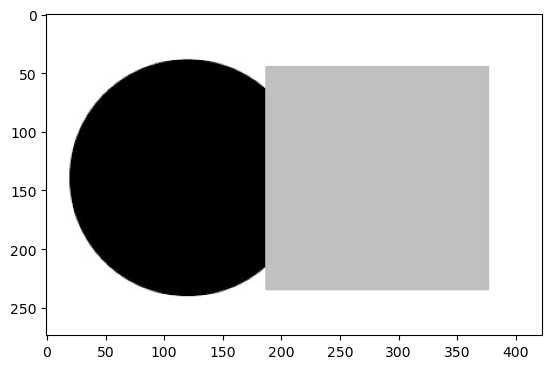

In [4]:
figuras = plt.imread("img/hist.jpg")
plt.imshow(figuras)
plt.show()

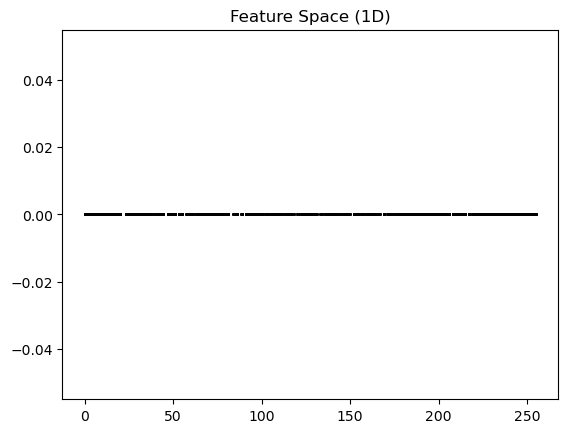

In [5]:
plt.scatter(figuras.flatten(),np.zeros(figuras.shape), c='black', s=1)
plt.title("Feature Space (1D)")
plt.show()

# Histograma de intensidades

Histograma de una imagen: $h(k) = n_k$, con $k\in \{0, \dots, L\}$ nivel de gris (para $L$ niveles de gris), y $n_k$ el número de píxeles de la imagen con valor de nivel de gris $k$.

<div align="center">
    <img src="img/histo.jpg" alt="" width="60%" align="center" />
</div>

- Es común también utilizar la versión normalizada del histograma en $(0,1)$: 

$$p(k) = \frac{n_k}{n}$$
con $n$ como el número total de píxeles en la imagen.

- Se puede decir que $p(k)$ es un estimador de la probabilidad de ocurrencia del nivel de gris $k$ en la imagen.

- Histogramas son herramientas importantes para segmentación de imágenes en tiempo real (simples y baratos de calcular).

In [6]:
histogram, bin_edges = np.histogram(list(figuras.flatten()), bins=256)

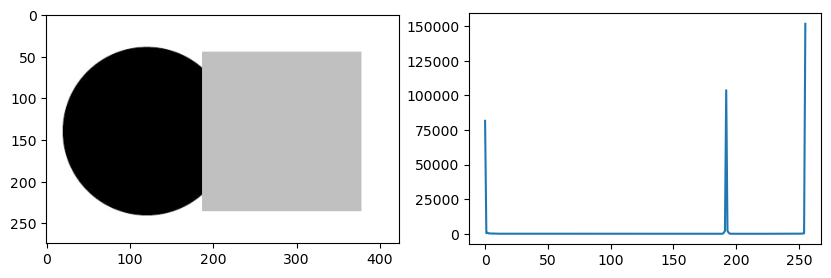

In [7]:
plt.figure(figsize=(10, 3))
plt.subplot(1,2,1)
plt.imshow(figuras)
plt.subplot(1,2,2)
plt.plot(histogram)
plt.show()

# Segmentation by thresholding

El método más simple de segmentación es la segmentación binaria por umbral.

Los píxeles con valor de intensidad menor a cierto umbral son 0 y los mayores o iguales al umbral son 1.

In [8]:
def plot_thresholding(image, t=0.5):
    binary=rgb2gray(image)
    binary[binary<t]=0
    binary[binary>=t]=1
    plt.imshow(binary)
    plt.show()

In [9]:
interact(plot_thresholding, image=fixed(figuras), t=(0,1,0.1));

interactive(children=(FloatSlider(value=0.5, description='t', max=1.0), Output()), _dom_classes=('widget-inter…

#### Agrupación de píxeles:

- 1D: Proximidad de la Intensidad.
- 3D: Proximidad de Color (RGB).

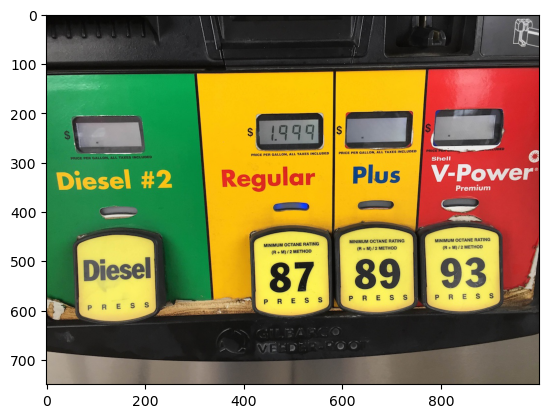

In [10]:
gas = plt.imread("img/gasoline.jpg")
plt.imshow(gas)
plt.show()

In [11]:
def plot_histogram_rgb(image):
    colors = ("red", "green", "blue")
    channel_ids = (0, 1, 2)
    plt.figure()
    plt.xlim([0, 256])
    for channel_id, c in zip(channel_ids, colors):
        histogram, bin_edges = np.histogram(image[:, :, channel_id], bins=256, range=(0, 256))
        plt.plot(bin_edges[0:-1], histogram, color=c)
    plt.show()

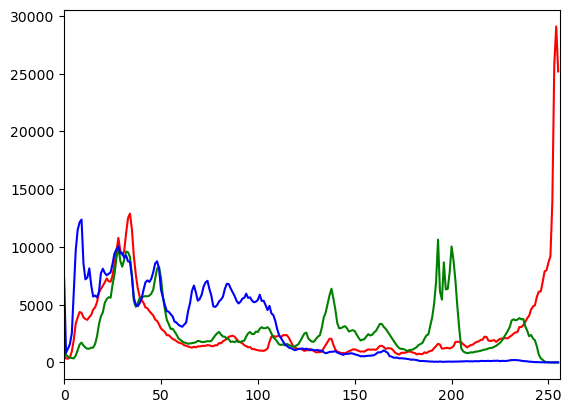

In [12]:
plot_histogram_rgb(gas)

In [13]:
def plot_space_rgb(image):
    # Reshape the image to a 2D array of pixels
    pixels = image.reshape((-1, 3))
    
    # Extract individual color channels
    r = pixels[:, 0]
    g = pixels[:, 1]
    b = pixels[:, 2]
    
    # Create a 3D scatter plot
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(r, g, b, marker='s', color='k', alpha=0.5)
    
    # Set labels for the axes
    ax.set_xlabel('Red')
    ax.set_ylabel('Green')
    ax.set_zlabel('Blue')
    
    plt.show()

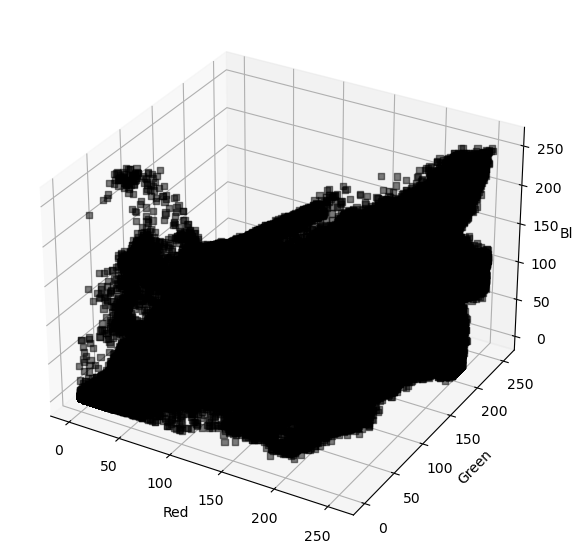

In [14]:
plot_space_rgb(gas)

# K-Means

- Es una técnica de clustering que puede ser utilizada para segmentar una imagen en $K$ grupos de píxeles con intensidad similar.
- El algoritmo asume la existencia de sólo $K$ clusters, que agrupan píxeles según algún criterio de distancia.

# Algoritmo K-Means para segmentación de imágenes
1. Escoger $K$ centroides de grupo, aleatoriamente o según algún otro criterio.
2. Asignar cada píxel de la imagen al centroide más cercano (menor distancia entre el píxel y el centroide).
3. Recalcular los centroides de los clusters promediando los píxeles de cada grupo.
4. Repetir 2 y 3 hasta converger (los píxeles no cambian de cluster entre iteraciones).

# Ejemplo práctico K-Means en Python

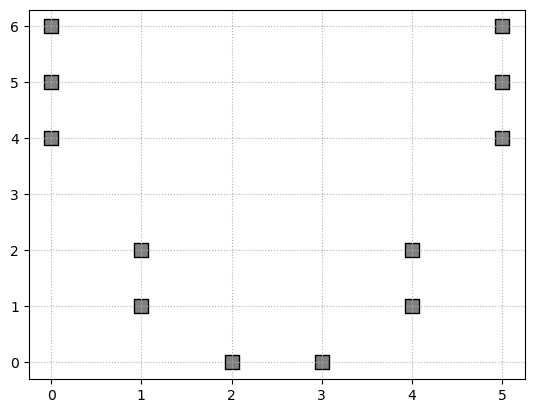

In [15]:
X = np.array([[0, 4], [0, 5], [0, 6], 
              [1, 1], [1, 2],
              [2, 0], [3, 0], 
              [4, 1], [4, 2],
              [5, 4], [5, 5], [5, 6], 
             ])
plt.scatter(X[:, 0], X[:, 1], marker='s', c='gray', s=100, edgecolors='k')
plt.grid(linestyle="dotted")
plt.show()

In [16]:
from plot_kmeans import plot_kmeans_example

In [17]:
interact(plot_kmeans_example, data=fixed(X), c1=fixed((1,3)), c2=fixed((1,7)), c3=fixed((5,3)), iterations=(0,5,1));

interactive(children=(IntSlider(value=0, description='iterations', max=5), Output()), _dom_classes=('widget-in…

# Color del cluster 

Determinando colores dominantes en la imagen.

In [18]:
def dominant_colors(image, k=2):
    clustering = KMeans(n_clusters=k).fit(image.reshape(-1,3))
    i = 0
    plt.figure(0,figsize=(15,3))
    plt.subplot(1,k+1,1)
    plt.imshow(image)
    plt.axis('off')
    for mean_color in clustering.cluster_centers_:
        plt.subplot(1,k+1,i+2)
        plt.axis("off")
        color = np.zeros((100,100,3),dtype='uint8')
        color[:,:,:] = mean_color
        plt.imshow(color)
        percentage = list(clustering.labels_).count(i)/len(clustering.labels_)
        plt.title(f"{round(percentage*100)}%")
        i += 1 

In [19]:
interact(dominant_colors, image=fixed(gas), k=(1,10));

interactive(children=(IntSlider(value=2, description='k', max=10, min=1), Output()), _dom_classes=('widget-int…

# Segmentación con K-Means

In [20]:
def plot_segmentation_kmeans(image, k=2):        
    clustering = KMeans(n_clusters=k).fit(image.reshape(-1,3))
    mean_colors = clustering.cluster_centers_.astype(np.uint8)
    segmented_image_mean_color = np.asarray([mean_colors[i] for i in clustering.labels_]).reshape(image.shape)    
    list_of_percentages = []
    for i in range(len(clustering.cluster_centers_)):
        percentage = list(clustering.labels_).count(i)/(len(clustering.labels_))
        list_of_percentages.append(percentage)
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121) 
    ax2 = fig.add_subplot(122)  
    ax1.imshow(segmented_image_mean_color)  
    ax1.axis('off')
    ax2.pie(list_of_percentages,colors=np.array(clustering.cluster_centers_/255),autopct="%1.0f%%")

In [21]:
interact(plot_segmentation_kmeans, image=fixed(gas), k=(2,10));

interactive(children=(IntSlider(value=2, description='k', max=10, min=2), Output()), _dom_classes=('widget-int…

In [22]:
bird = plt.imread('img/bird.jpg')

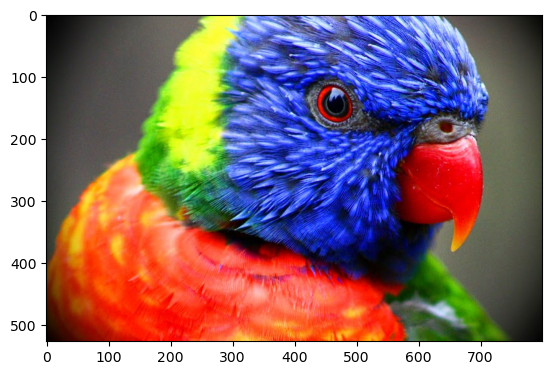

In [23]:
plt.imshow(bird)
plt.show()

In [24]:
interact(plot_segmentation_kmeans, image=fixed(bird), k=(2,10));

interactive(children=(IntSlider(value=2, description='k', max=10, min=2), Output()), _dom_classes=('widget-int…

In [25]:
chili = plt.imread('img/chili.jpeg')

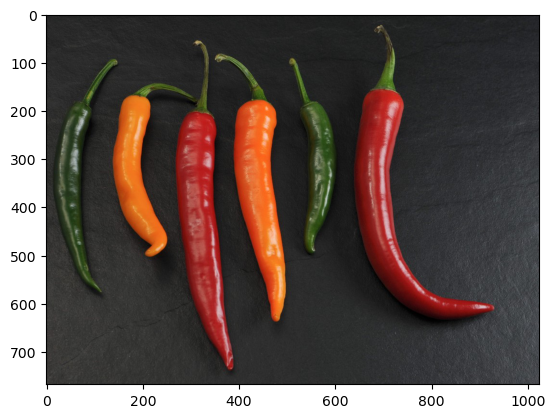

In [26]:
plt.imshow(chili)
plt.show()

In [27]:
interact(plot_segmentation_kmeans, image=fixed(chili), k=(2,10));

interactive(children=(IntSlider(value=2, description='k', max=10, min=2), Output()), _dom_classes=('widget-int…

# Segmentación basada en superpíxeles

Esta técnica se basa en usar clustering para extraer “superpixels” de una imagen.

# ¿Qué es un superpíxel?

Grupo de píxeles que comparten características comunes (como la intensidad).

Ventajas:
- Entregan más información que los píxeles individuales. 
- Tienen un significado perceptivo ya que los píxeles que pertenecen a un superpíxel comparten propiedades visuales similares. 
- Proporcionan una representación conveniente y compacta de imágenes que puede ser muy útil para problemas computacionalmente exigentes.

# Simple Linear Iterative Clustering (SLIC)

- Modificación de K-Means para generar superpíxeles.
- SLIC asigna cada píxel a un vector de 5 dimensiones que contiene tres componentes de color y dos coordenadas espaciales.
$$ \mathbf{z} = \begin{bmatrix}
  R \\
  G \\
  B \\
  x \\
  y \\
\end{bmatrix}  $$

donde $(R, G, B)$ son las tres componentes de color del píxel y $(x, y)$ son sus dos coordenadas espaciales.

# Principales etapas de SLIC

Sea $N$ el número total de píxeles en la imagen y $K$ el número deseado de superpíxeles,

1. Inicializar $K$ centroides $\mathbf{c}_k = \begin{bmatrix}
  R_k & G_k & B_k & x_k & y_k \\ \end{bmatrix}^T$ en una cuadrícula regular, donde cada celda tiene tamaño $S = \sqrt{\frac{N}{K}}$, y cada superpíxel tiene aproximadamente $\frac{N}{K}$ píxeles.

Por ejemplo,

<div align="center">
    <img src="img/SLICexample.jpg" alt="" width="70%" align="center" />
</div>

**Paso 1:** Inicializar $K$ centroides en la cuadrícula regular , donde cada celda tiene tamaño $S = \sqrt{\frac{N}{K}}$, y cada superpíxel tiene aproximadamente $\frac{N}{K}$ píxeles.
<div align="center">
    <img src="img/step1.jpg" alt="" width="60%" align="center" />
</div>

# Principales etapas de SLIC

2. Mover los centroides iniciales a las posiciones con menor gradiente. Esto se hace para evitar centrar un superpíxel en un borde.

<div align="center">
    <img src="img/step2.jpg" alt="" width="30%" align="center" />
</div>

# Principales etapas de SLIC

3. Asignar cada píxel a su centroide más cercano en un espacio de búsqueda local definido por un vecindario de $2S \times 2S$.

<div align="center">
    <img src="img/diferencia.jpg" alt="" width="50%" align="center" />
</div>

Siguiendo con el ejemplo, el **paso 3** sería:

<div align="center">
    <img src="img/step3.png" alt="" width="70%" align="center" />
</div>

# Principales etapas de SLIC

4. Actualizar la ubicación de los centroides como el promedio entre todos los píxeles dentro del cluster correspondiente.
5. Repetir etapas **(3)** y **(4)** hasta lograr convergencia.

<div align="center">
    <img src="img/iterations.jpg" alt="" width="80%" align="center" />
</div>

# Ejemplo SLIC en Python

In [28]:
from skimage.segmentation import slic

In [29]:
def plot_slic(image, n_segments=3, sigma=0, compactness=10):
    segments = slic(image, n_segments=n_segments, sigma=sigma, start_label=0, compactness=compactness)
    
    # Calculate mean colors for each segment
    unique_labels = np.unique(segments)
    mean_colors = np.array([np.mean(image[segments == label], axis=0) for label in unique_labels])
    
    # Assign mean colors to each pixel in the segmented image
    segmented_image_mean_color = mean_colors[segments]
    
    fig = plt.figure(figsize=(13, 5))
    ax1 = fig.add_subplot(121) 
    ax2 = fig.add_subplot(122)  
    ax1.imshow(image)
    ax1.contour(segments, colors='yellow')
    ax1.axis('off')
    ax2.imshow(segmented_image_mean_color.astype(np.uint8))
    ax2.axis('off')
    
    plt.show()

In [30]:
interact(plot_slic, image=fixed(bird), n_segments=[5,10,20,100], sigma=fixed(0), compactness=[1,5,10,20,100]);

interactive(children=(Dropdown(description='n_segments', options=(5, 10, 20, 100), value=5), Dropdown(descript…